In [5]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pywt

sys.path.insert(0, str(Path("../src").resolve()))

from fmlab.datatools.transforms import WaveletScalogram

In [6]:
dataset_path = Path("../artifacts/datasets/wesad_256_512_null_ecg")
annotations = pd.read_csv(dataset_path / "annotations.csv")
baseline_annotation = annotations[annotations["label"] == 0].iloc[0]
tsst_annotation = annotations[(annotations["label"] == 1) & (annotations["group"] == baseline_annotation["group"])].iloc[0]
baseline_sample = np.load(dataset_path / baseline_annotation["file"], allow_pickle=False)
tsst_sample = np.load(dataset_path / tsst_annotation["file"], allow_pickle=False)


In [7]:
transform = WaveletScalogram(fs=256, wavelet="cmor1.5-1.0", min_frequency=1, max_frequency=65, num_frequencies=100)
morl_transform = WaveletScalogram(fs=256, wavelet="morl", min_frequency=1, max_frequency=65, num_frequencies=100)
mexh_transform = WaveletScalogram(fs=256, wavelet="mexh", min_frequency=1, max_frequency=65, num_frequencies=100)
gaus1_transform = WaveletScalogram(fs=256, wavelet="gaus1", min_frequency=1, max_frequency=65, num_frequencies=100)

### Wavelets

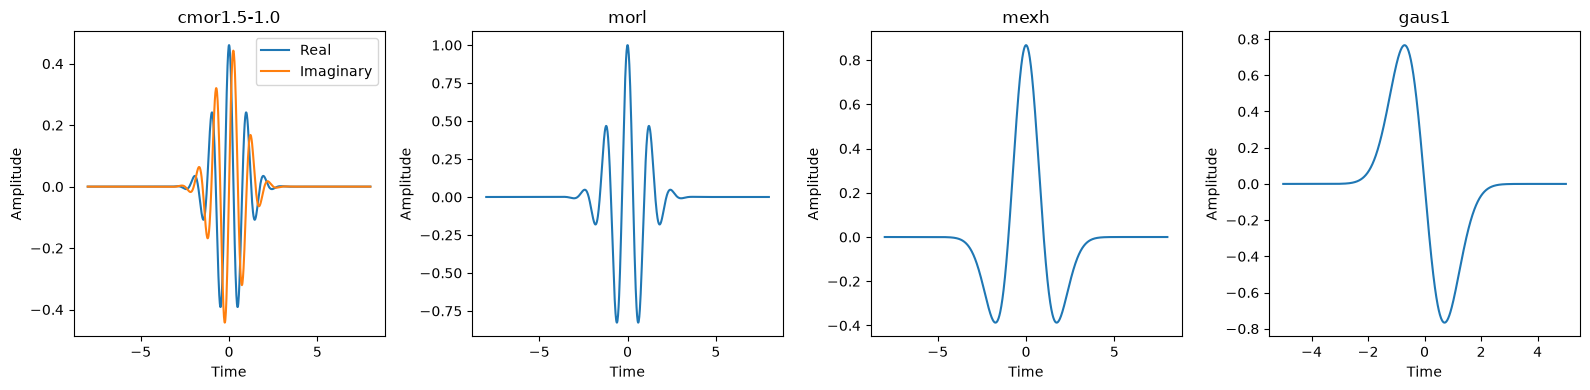

In [8]:
cmor_values, cmor_time = pywt.ContinuousWavelet(transform.wavelet).wavefun(length=1024)
morl_values, morl_time = pywt.ContinuousWavelet(morl_transform.wavelet).wavefun(length=1024)
mexh_values, mexh_time = pywt.ContinuousWavelet(mexh_transform.wavelet).wavefun(length=1024)
gaus1_values, gaus1_time = pywt.ContinuousWavelet(gaus1_transform.wavelet).wavefun(length=1024)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].plot(cmor_time, np.real(cmor_values), label="Real")
axes[0].plot(cmor_time, np.imag(cmor_values), label="Imaginary")
axes[0].set_title("cmor1.5-1.0")
axes[0].set_xlabel("Time")
axes[0].set_ylabel("Amplitude")
axes[0].legend()
axes[1].plot(morl_time, morl_values)
axes[1].set_title("morl")
axes[1].set_xlabel("Time")
axes[1].set_ylabel("Amplitude")
axes[2].plot(mexh_time, mexh_values)
axes[2].set_title("mexh")
axes[2].set_xlabel("Time")
axes[2].set_ylabel("Amplitude")
axes[3].plot(gaus1_time, gaus1_values)
axes[3].set_title("gaus1")
axes[3].set_xlabel("Time")
axes[3].set_ylabel("Amplitude")
plt.tight_layout()
plt.show()

### Signals

**Baseline**

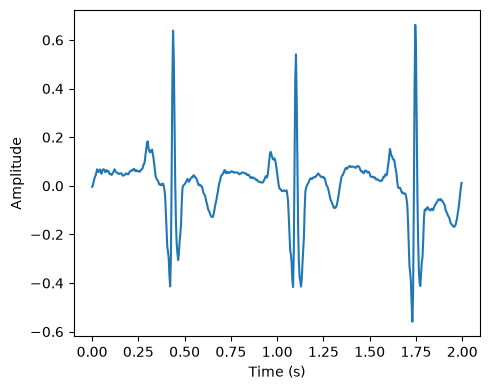

In [9]:
plt.figure(figsize=(5, 4))
plt.plot(np.arange(baseline_sample.squeeze().size) / transform.fs, baseline_sample.squeeze())
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.tight_layout()
plt.show()

**TSST**

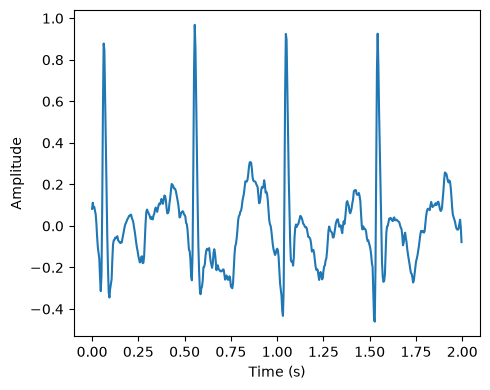

In [10]:
plt.figure(figsize=(5, 4))
plt.plot(np.arange(tsst_sample.squeeze().size) / transform.fs, tsst_sample.squeeze())
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.tight_layout()
plt.show()

### cmor1.5-1.0

**Baseline**

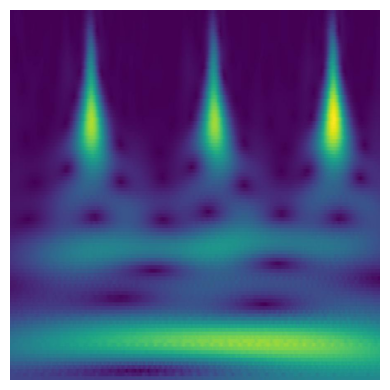

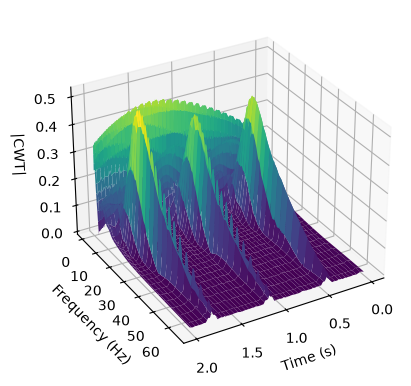

In [ ]:
cmor_baseline_image = transform(baseline_sample)
cmor_baseline_coefficients, cmor_baseline_frequencies = pywt.cwt(baseline_sample.squeeze(), transform.widths, transform.wavelet, sampling_period=1 / transform.fs)
cmor_baseline_magnitude = np.abs(cmor_baseline_coefficients)
cmor_baseline_time = np.arange(cmor_baseline_magnitude.shape[1]) / transform.fs
cmor_baseline_time_grid, cmor_baseline_frequency_grid = np.meshgrid(cmor_baseline_time, cmor_baseline_frequencies)

fig, ax1 = plt.subplots(figsize=(5, 4))
ax1.imshow(cmor_baseline_image)
ax1.axis("off")
plt.tight_layout()
plt.show()

fig = plt.figure(figsize=(5, 4))
ax2 = fig.add_subplot(111, projection="3d")
ax2.plot_surface(cmor_baseline_time_grid, cmor_baseline_frequency_grid, cmor_baseline_magnitude, cmap="viridis")
ax2.set_xlabel("Time (s)")
ax2.set_ylabel("Frequency (Hz)")
ax2.set_zlabel("|CWT|")
ax2.view_init(elev=30, azim=60)
plt.tight_layout()
plt.show()

**TSST**

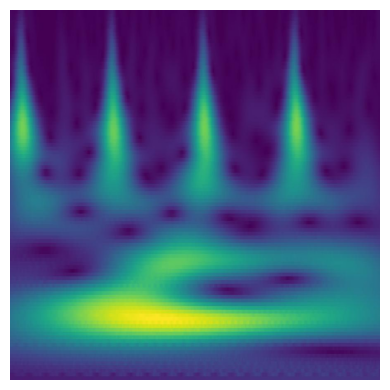

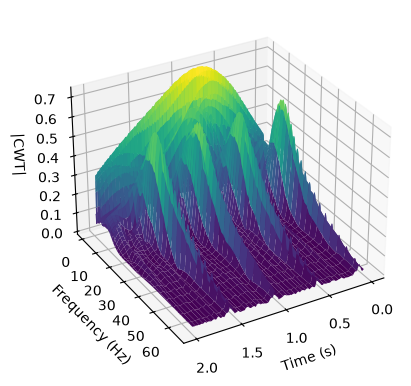

In [12]:
cmor_tsst_image = transform(tsst_sample)
cmor_tsst_coefficients, cmor_tsst_frequencies = pywt.cwt(tsst_sample.squeeze(), transform.widths, transform.wavelet, sampling_period=1 / transform.fs)
cmor_tsst_magnitude = np.abs(cmor_tsst_coefficients)
cmor_tsst_time = np.arange(cmor_tsst_magnitude.shape[1]) / transform.fs
cmor_tsst_time_grid, cmor_tsst_frequency_grid = np.meshgrid(cmor_tsst_time, cmor_tsst_frequencies)

fig, ax1 = plt.subplots(figsize=(5, 4))
ax1.imshow(cmor_tsst_image)
ax1.axis("off")
plt.tight_layout()
plt.show()

fig = plt.figure(figsize=(5, 4))
ax2 = fig.add_subplot(111, projection="3d")
ax2.plot_surface(cmor_tsst_time_grid, cmor_tsst_frequency_grid, cmor_tsst_magnitude, cmap="viridis")
ax2.set_xlabel("Time (s)")
ax2.set_ylabel("Frequency (Hz)")
ax2.set_zlabel("|CWT|")
ax2.view_init(elev=30, azim=60)
plt.tight_layout()
plt.show()

### morl

**Baseline**

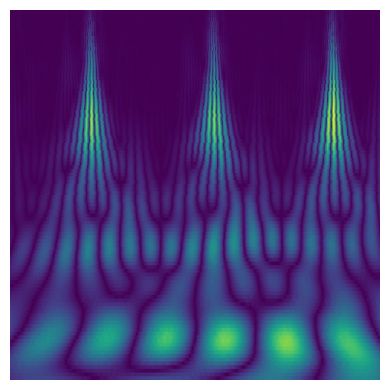

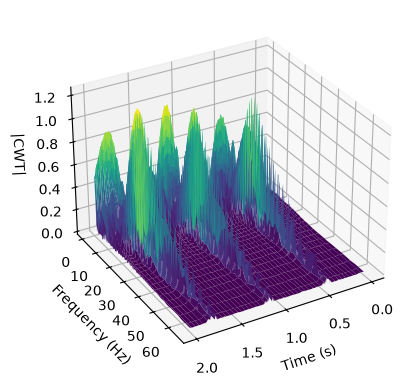

In [13]:
morl_baseline_image = morl_transform(baseline_sample)
morl_baseline_coefficients, morl_baseline_frequencies = pywt.cwt(baseline_sample.squeeze(), morl_transform.widths, morl_transform.wavelet, sampling_period=1 / morl_transform.fs)
morl_baseline_magnitude = np.abs(morl_baseline_coefficients)
morl_baseline_time = np.arange(morl_baseline_magnitude.shape[1]) / morl_transform.fs
morl_baseline_time_grid, morl_baseline_frequency_grid = np.meshgrid(morl_baseline_time, morl_baseline_frequencies)

fig, ax1 = plt.subplots(figsize=(5, 4))
ax1.imshow(morl_baseline_image)
ax1.axis("off")
plt.tight_layout()
plt.show()

fig = plt.figure(figsize=(5, 4))
ax2 = fig.add_subplot(111, projection="3d")
ax2.plot_surface(morl_baseline_time_grid, morl_baseline_frequency_grid, morl_baseline_magnitude, cmap="viridis")
ax2.set_xlabel("Time (s)")
ax2.set_ylabel("Frequency (Hz)")
ax2.set_zlabel("|CWT|")
ax2.view_init(elev=30, azim=60)
plt.tight_layout()
plt.show()

**TSST**

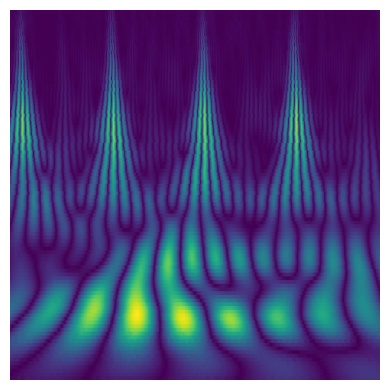

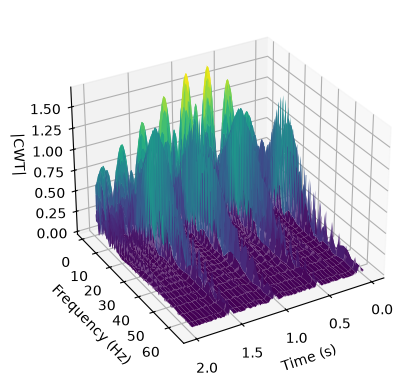

In [14]:
morl_tsst_image = morl_transform(tsst_sample)
morl_tsst_coefficients, morl_tsst_frequencies = pywt.cwt(tsst_sample.squeeze(), morl_transform.widths, morl_transform.wavelet, sampling_period=1 / morl_transform.fs)
morl_tsst_magnitude = np.abs(morl_tsst_coefficients)
morl_tsst_time = np.arange(morl_tsst_magnitude.shape[1]) / morl_transform.fs
morl_tsst_time_grid, morl_tsst_frequency_grid = np.meshgrid(morl_tsst_time, morl_tsst_frequencies)

fig, ax1 = plt.subplots(figsize=(5, 4))
ax1.imshow(morl_tsst_image)
ax1.axis("off")
plt.tight_layout()
plt.show()

fig = plt.figure(figsize=(5, 4))
ax2 = fig.add_subplot(111, projection="3d")
ax2.plot_surface(morl_tsst_time_grid, morl_tsst_frequency_grid, morl_tsst_magnitude, cmap="viridis")
ax2.set_xlabel("Time (s)")
ax2.set_ylabel("Frequency (Hz)")
ax2.set_zlabel("|CWT|")
ax2.view_init(elev=30, azim=60)
plt.tight_layout()
plt.show()

### mexh

**Baseline**

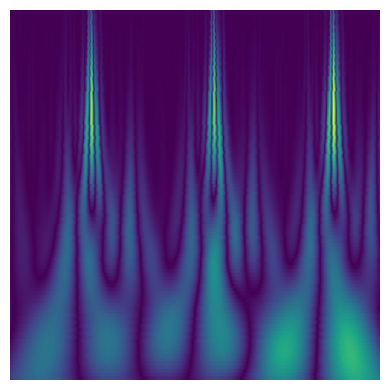

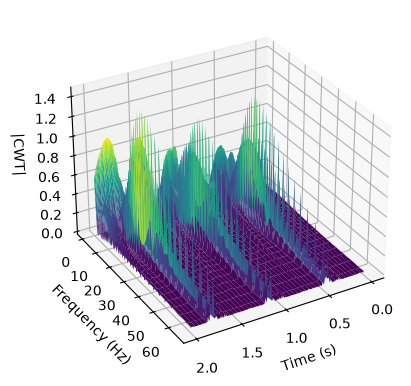

In [15]:
mexh_baseline_image = mexh_transform(baseline_sample)
mexh_baseline_coefficients, mexh_baseline_frequencies = pywt.cwt(baseline_sample.squeeze(), mexh_transform.widths, mexh_transform.wavelet, sampling_period=1 / mexh_transform.fs)
mexh_baseline_magnitude = np.abs(mexh_baseline_coefficients)
mexh_baseline_time = np.arange(mexh_baseline_magnitude.shape[1]) / mexh_transform.fs
mexh_baseline_time_grid, mexh_baseline_frequency_grid = np.meshgrid(mexh_baseline_time, mexh_baseline_frequencies)

fig, ax1 = plt.subplots(figsize=(5, 4))
ax1.imshow(mexh_baseline_image)
ax1.axis("off")
plt.tight_layout()
plt.show()

fig = plt.figure(figsize=(5, 4))
ax2 = fig.add_subplot(111, projection="3d")
ax2.plot_surface(mexh_baseline_time_grid, mexh_baseline_frequency_grid, mexh_baseline_magnitude, cmap="viridis")
ax2.set_xlabel("Time (s)")
ax2.set_ylabel("Frequency (Hz)")
ax2.set_zlabel("|CWT|")
ax2.view_init(elev=30, azim=60)
plt.tight_layout()
plt.show()

**TSST**

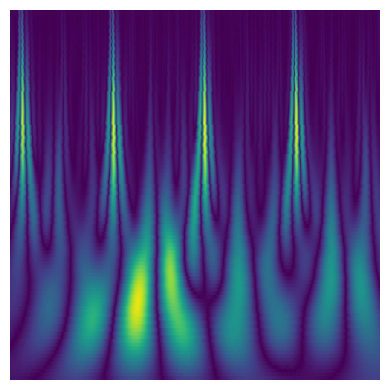

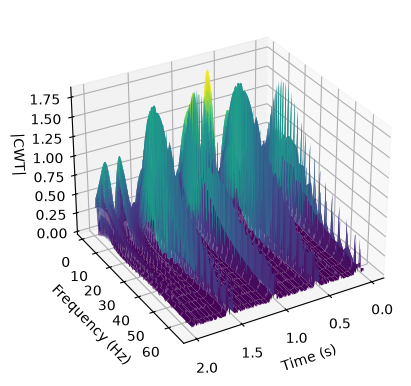

In [16]:
mexh_tsst_image = mexh_transform(tsst_sample)
mexh_tsst_coefficients, mexh_tsst_frequencies = pywt.cwt(tsst_sample.squeeze(), mexh_transform.widths, mexh_transform.wavelet, sampling_period=1 / mexh_transform.fs)
mexh_tsst_magnitude = np.abs(mexh_tsst_coefficients)
mexh_tsst_time = np.arange(mexh_tsst_magnitude.shape[1]) / mexh_transform.fs
mexh_tsst_time_grid, mexh_tsst_frequency_grid = np.meshgrid(mexh_tsst_time, mexh_tsst_frequencies)

fig, ax1 = plt.subplots(figsize=(5, 4))
ax1.imshow(mexh_tsst_image)
ax1.axis("off")
plt.tight_layout()
plt.show()

fig = plt.figure(figsize=(5, 4))
ax2 = fig.add_subplot(111, projection="3d")
ax2.plot_surface(mexh_tsst_time_grid, mexh_tsst_frequency_grid, mexh_tsst_magnitude, cmap="viridis")
ax2.set_xlabel("Time (s)")
ax2.set_ylabel("Frequency (Hz)")
ax2.set_zlabel("|CWT|")
ax2.view_init(elev=30, azim=60)
plt.tight_layout()
plt.show()

### gaus1

**Baseline**

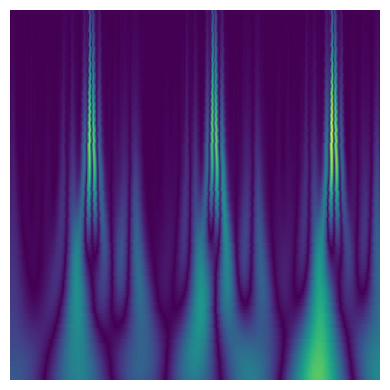

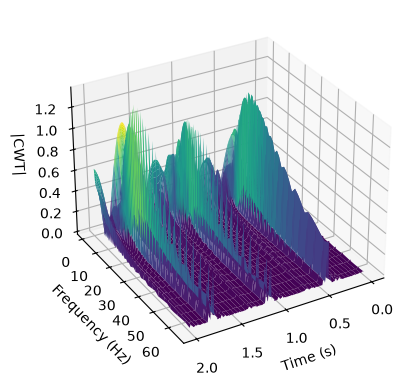

In [17]:
gaus1_baseline_image = gaus1_transform(baseline_sample)
gaus1_baseline_coefficients, gaus1_baseline_frequencies = pywt.cwt(baseline_sample.squeeze(), gaus1_transform.widths, gaus1_transform.wavelet, sampling_period=1 / gaus1_transform.fs)
gaus1_baseline_magnitude = np.abs(gaus1_baseline_coefficients)
gaus1_baseline_time = np.arange(gaus1_baseline_magnitude.shape[1]) / gaus1_transform.fs
gaus1_baseline_time_grid, gaus1_baseline_frequency_grid = np.meshgrid(gaus1_baseline_time, gaus1_baseline_frequencies)

fig, ax1 = plt.subplots(figsize=(5, 4))
ax1.imshow(gaus1_baseline_image)
ax1.axis("off")
plt.tight_layout()
plt.show()

fig = plt.figure(figsize=(5, 4))
ax2 = fig.add_subplot(111, projection="3d")
ax2.plot_surface(gaus1_baseline_time_grid, gaus1_baseline_frequency_grid, gaus1_baseline_magnitude, cmap="viridis")
ax2.set_xlabel("Time (s)")
ax2.set_ylabel("Frequency (Hz)")
ax2.set_zlabel("|CWT|")
ax2.view_init(elev=30, azim=60)
plt.tight_layout()
plt.show()

**TSST**

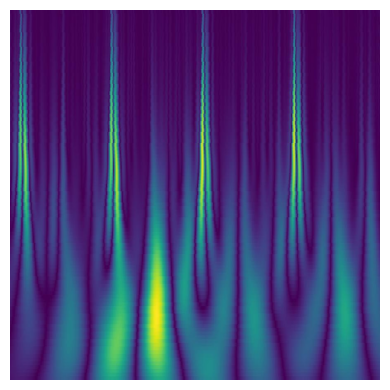

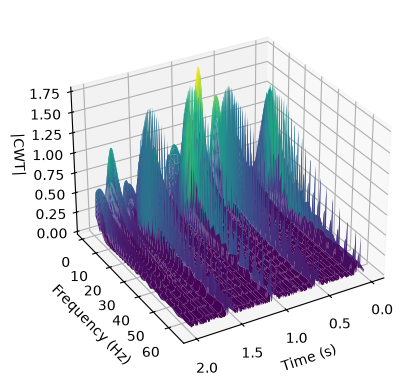

In [18]:
gaus1_tsst_image = gaus1_transform(tsst_sample)
gaus1_tsst_coefficients, gaus1_tsst_frequencies = pywt.cwt(tsst_sample.squeeze(), gaus1_transform.widths, gaus1_transform.wavelet, sampling_period=1 / gaus1_transform.fs)
gaus1_tsst_magnitude = np.abs(gaus1_tsst_coefficients)
gaus1_tsst_time = np.arange(gaus1_tsst_magnitude.shape[1]) / gaus1_transform.fs
gaus1_tsst_time_grid, gaus1_tsst_frequency_grid = np.meshgrid(gaus1_tsst_time, gaus1_tsst_frequencies)

fig, ax1 = plt.subplots(figsize=(5, 4))
ax1.imshow(gaus1_tsst_image)
ax1.axis("off")
plt.tight_layout()
plt.show()

fig = plt.figure(figsize=(5, 4))
ax2 = fig.add_subplot(111, projection="3d")
ax2.plot_surface(gaus1_tsst_time_grid, gaus1_tsst_frequency_grid, gaus1_tsst_magnitude, cmap="viridis")
ax2.set_xlabel("Time (s)")
ax2.set_ylabel("Frequency (Hz)")
ax2.set_zlabel("|CWT|")
ax2.view_init(elev=30, azim=60)
plt.tight_layout()
plt.show()